In [329]:
from oandapyV20 import API
from dotenv import load_dotenv
import os
from oandapyV20.endpoints.instruments import InstrumentsCandles
import pandas as pd
import numpy as np

load_dotenv()
instrument = "EUR_USD"

In [330]:
client = API(access_token=os.getenv("OANDA_API_KEY"))
client

In [331]:
import oandapyV20.endpoints.accounts as accounts

r = accounts.AccountDetails(os.getenv("OANDA_ACCOUNT_ID"))
client.request(r)
r.response

{'account': {'guaranteedStopLossOrderMode': 'DISABLED',
  'hedgingEnabled': False,
  'id': '101-001-39008384-001',
  'createdTime': '2026-04-07T17:10:59.709260032Z',
  'currency': 'USD',
  'createdByUserID': 39008384,
  'alias': 'Primary',
  'marginRate': '0.02',
  'lastTransactionID': '3',
  'balance': '100000.0000',
  'openTradeCount': 0,
  'openPositionCount': 0,
  'pendingOrderCount': 0,
  'pl': '0.0000',
  'resettablePL': '0.0000',
  'resettablePLTime': '0',
  'financing': '0.0000',
  'commission': '0.0000',
  'dividendAdjustment': '0',
  'guaranteedExecutionFees': '0.0000',
  'orders': [],
  'positions': [],
  'trades': [],
  'trueUnrealizedPL': '0.0000',
  'unrealizedPL': '0.0000',
  'trueNAV': '100000.0000',
  'NAV': '100000.0000',
  'marginUsed': '0.0000',
  'marginAvailable': '100000.0000',
  'positionValue': '0.0000',
  'marginCloseoutUnrealizedPL': '0.0000',
  'marginCloseoutNAV': '100000.0000',
  'marginCloseoutMarginUsed': '0.0000',
  'marginCloseoutPositionValue': '0.000

In [332]:
def get_candles(tf):
    params = {
        "granularity": tf,
        "count": 1000
    }

    request = InstrumentsCandles(
        instrument=instrument,
        params=params
    )

    candles = client.request(request)['candles']

    data = []

    for c in candles:
        if c["complete"]:
            data.append({
                "time": c["time"],
                "open": float(c["mid"]["o"]),
                "high": float(c["mid"]["h"]),
                "low": float(c["mid"]["l"]),
                "close": float(c["mid"]["c"])
            })

    df = pd.DataFrame(data)
    df["time"] = pd.to_datetime(df["time"])

    return df

In [333]:
def calculate_indicators(df):
    # Trend Indicators
    df["EMA_5"] = df["close"].ewm(span=5, adjust=False).mean()
    df["EMA_8"] = df["close"].ewm(span=8, adjust=False).mean()
    df["EMA_20"] = df["close"].ewm(span=20, adjust=False).mean()

    df["ema_trend"] = df["EMA_5"] - df["EMA_20"]

    # Return / momentum indicators
    df["return"] = df["close"].pct_change()
    df["mom_3"] = df["close"] - df["close"].shift(3)
    df["mom_5"] = df["close"] - df["close"].shift(5)

    # Volatility indicators
    df["volatility_10"] = df["return"].rolling(10).std()
    df["volatility_20"] = df["return"].rolling(20).std()

    # ATR
    df["prev_close"] = df["close"].shift(1)

    df["tr1"] = df["high"] - df["low"]
    df["tr2"] = abs(df["high"] - df["prev_close"])
    df["tr3"] = abs(df["low"] - df["prev_close"])

    df["TR"] = df[["tr1", "tr2", "tr3"]].max(axis=1)
    df["ATR_14"] = df["TR"].rolling(14).mean()

    # RSI
    delta = df["close"].diff()
    gain = (delta.where(delta > 0, 0)).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(14).mean()

    rs = gain / loss
    df["RSI_14"] = 100 - (100 / (1 + rs))

    # Bollinger Bands
    mid = df["close"].rolling(20).mean()
    std = df["close"].rolling(20).std()

    df["bb_upper"] = mid + 2 * std
    df["bb_lower"] = mid - 2 * std

    df["bb_position"] = (df["close"] - df["bb_lower"]) / (df["bb_upper"] - df["bb_lower"])

    # breakouts
    df["high_10"] = df["high"].rolling(10).max()
    df["low_10"] = df["low"].rolling(10).min()

    df["breakout_up"] = (df["close"] > df["high_10"]).astype(int)
    df["breakout_down"] = (df["close"] < df["low_10"]).astype(int)

    # price position vs EMA
    df["price_vs_ema8"] = (df["close"] - df["EMA_8"]) / df["EMA_8"]

    return df

In [334]:
df = get_candles("M5")

df = calculate_indicators(df)

df["target"] = (df["close"].shift(-1) > df["close"]).astype(int)

df = df.dropna()

features = [
    # Trend
    "EMA_5",
    "EMA_8",
    "EMA_20",
    "ema_trend",

    # Momentum
    "return",
    "mom_3",
    "mom_5",

    # Volatility
    "volatility_10",
    "volatility_20",
    "ATR_14",

    # RSI
    "RSI_14",

    # Bollinger
    "bb_position",

    # Breakouts
    "breakout_up",
    "breakout_down",

    # Price structure
    "price_vs_ema8"
]

X = df[features]
y = df["target"]

In [335]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

In [336]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

In [337]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, predictions)
print("Accuracy:", accuracy)

Accuracy: 0.5


In [338]:
test_df = df.loc[y_test.index].copy()

test_df["predictions"] = predictions
test_df["future_return"] = test_df["close"].shift(-1) / test_df["close"] - 1

test_df["strategy_return"] = np.where(
    test_df["predictions"] == 1, test_df["future_return"], -test_df["future_return"]
)

test_df = test_df.dropna()

test_df["equity_curve"] = (1 + test_df["strategy_return"]).cumprod()

total_return = test_df["equity_curve"].iloc[-1] - 1
win_rate = (test_df["strategy_return"] > 0).mean()
trades = len(test_df)

print("Total Return:", round(total_return * 100, 2), "%")
print("Win Rate:", round(win_rate * 100, 2), "%")
print("Number of Trades:", trades)

Total Return: -0.14 %
Win Rate: 48.21 %
Number of Trades: 195


In [339]:
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

print("Train:", accuracy_score(y_train, train_preds))
print("Test:", accuracy_score(y_test, test_preds))

Train: 0.5267857142857143
Test: 0.5


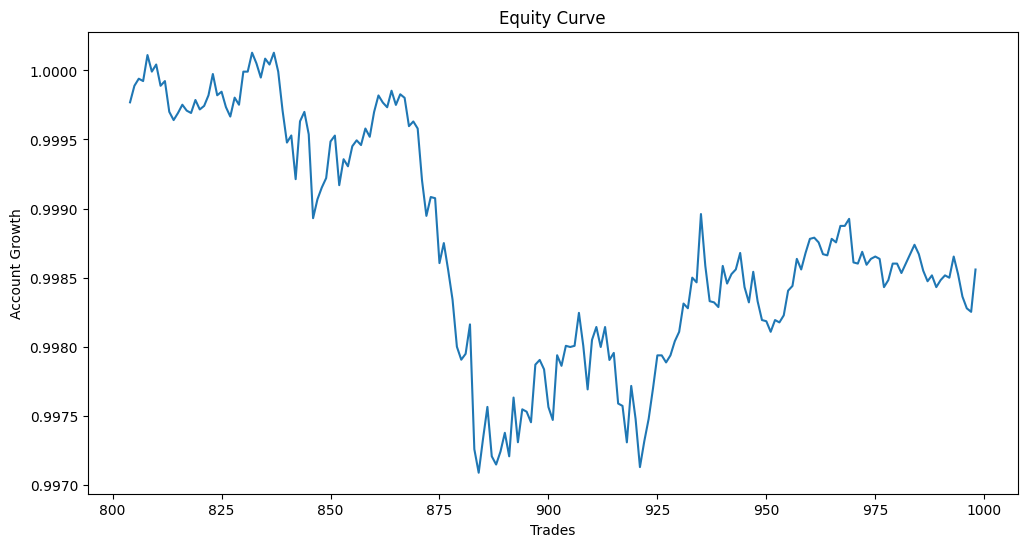

In [340]:
import matplotlib.pyplot as plt

test_df["equity_curve"].plot(figsize = (12,6), title="Equity Curve")
plt.xlabel("Trades")
plt.ylabel("Account Growth")
plt.show()